In [2]:
import pandas as pd

# Load all datasets
sales = pd.read_csv("sales-data.csv")
products = pd.read_csv("products.csv")
people = pd.read_csv("people-tel.csv")
geo = pd.read_csv("geo.csv")

# Quick peek at the first 3 rows of each table
print("--- SALES DATA ---")
display(sales.head(3))

print("--- PRODUCTS DATA ---")
display(products.head(3))

print("--- PEOPLE DATA ---")
display(people.head(3))

print("--- GEO DATA ---")
display(geo.head(3)) 

--- SALES DATA ---


,Sales Person,Geo,Product,Date,Amount,Boxes
0,SP01,G4,P04,2022-07-01,8414,495
1,SP02,G3,P14,2022-07-01,532,54
2,SP12,G2,P08,2022-07-01,5376,269


--- PRODUCTS DATA ---


,Product ID,Product,Category,Size,Cost per Box
0,P01,Milk Bars,Bars,LARGE,1.52
1,P02,50% Dark Bites,Bites,LARGE,2.57
2,P03,Almond Choco,Bars,LARGE,9.60


--- PEOPLE DATA ---


,Sales Person,SP ID,Team,Location
0,Ramalingam Kothapeta,SP01,Yummies,Hyderabad
1,Devsena Veluvalapalli,SP02,Yummies,Hyderabad
2,Parasuramudu Jamakayala,SP03,Yummies,Hyderabad


--- GEO DATA ---


,GeoID,Geo,Region
0,G1,India,APAC
1,G2,USA,Americas
2,G3,Canada,Americas


In [3]:
# 1. Merge Sales with People
df = sales.merge(people, left_on='Sales Person', right_on='SP ID', how='left')

# 2. Merge with Geo
df = df.merge(geo, left_on='Geo', right_on='GeoID', how='left')

# 3. Merge with Products
df = df.merge(products, left_on='Product', right_on='Product ID', how='left')

# 4. Calculate total cost and profit for each sale
df['Total Cost'] = df['Boxes'] * df['Cost per Box']
df['Profit'] = df['Amount'] - df['Total Cost']

# Take a look at all column names to see what we have
print("All columns in merged dataset:\n", df.columns.tolist())

# Display the first 5 rows of our master dataset
display(df.head(5))

All columns in merged dataset:
 ['Sales Person_x', 'Geo_x', 'Product_x', 'Date', 'Amount', 'Boxes', 'Sales Person_y', 'SP ID', 'Team', 'Location', 'GeoID', 'Geo_y', 'Region', 'Product ID', 'Product_y', 'Category', 'Size', 'Cost per Box', 'Total Cost', 'Profit']


,Sales Person_x,Geo_x,Product_x,Date,Amount,Boxes,Sales Person_y,SP ID,Team,Location,GeoID,Geo_y,Region,Product ID,Product_y,Category,Size,Cost per Box,Total Cost,Profit
0,SP01,G4,P04,2022-07-01,8414,495,Ramalingam Kothapeta,SP01,Yummies,Hyderabad,G4,New Zealand,APAC,P04,Raspberry Choco,Bars,LARGE,4.09,2024.55,6389.45
1,SP02,G3,P14,2022-07-01,532,54,Devsena Veluvalapalli,SP02,Yummies,Hyderabad,G3,Canada,Americas,P14,White Choc,Other,SMALL,0.16,8.64,523.36
2,SP12,G2,P08,2022-07-01,5376,269,Venkat Kodi,SP12,Yummies,Wellington,G2,USA,Americas,P08,99% Dark & Pure,Bars,LARGE,2.47,664.43,4711.57
3,SP01,G4,P15,2022-07-01,259,22,Ramalingam Kothapeta,SP01,Yummies,Hyderabad,G4,New Zealand,APAC,P15,Baker's Choco Chips,Bars,SMALL,3.40,74.80,184.20
4,SP19,G2,P18,2022-07-01,5530,179,Devrat Damarsingh,SP19,Jucies,Seattle,G2,USA,Americas,P18,Manuka Honey Choco,Other,SMALL,4.75,850.25,4679.75


In [4]:
# Group by product category and sum up the total profit
category_profit = df.groupby('Category')['Profit'].sum().reset_index()

# Sort the results from highest profit to lowest profit
category_profit = category_profit.sort_values(by='Profit', ascending=False)

# Display the sorted summary table
display(category_profit) 

,Category,Profit
0,Bars,16820302.97
1,Bites,10424515.47
2,Other,6659627.87


In [5]:
# Group by geographic Region and sum up total sales amount
region_sales = df.groupby('Region')['Amount'].sum().reset_index()

# Sort from highest to lowest revenue
region_sales = region_sales.sort_values(by='Amount', ascending=False)

# Display the result
display(region_sales)

,Region,Amount
0,APAC,22009323
1,Americas,14362614
2,Europe,7189609


C:\Users\akshaya\AppData\Local\Temp\ipykernel_26784\1987020357.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_profit, x='Category', y='Profit', palette='crest')


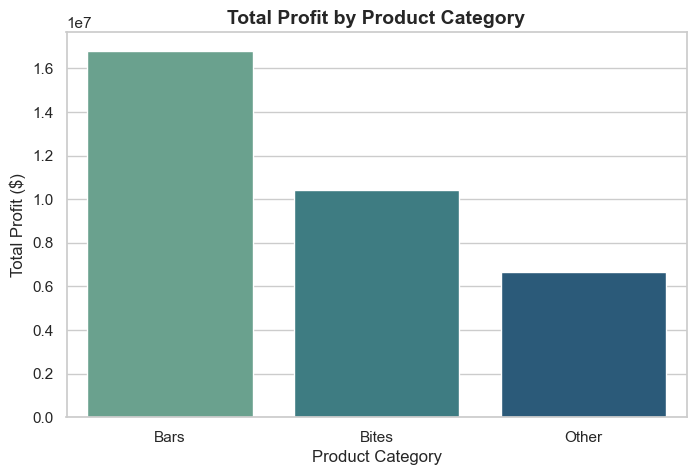

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for our charts
sns.set_theme(style="whitegrid")

# Create a bar chart for Category Profit
plt.figure(figsize=(8, 5))
sns.barplot(data=category_profit, x='Category', y='Profit', palette='crest')

# Add clean titles and labels
plt.title('Total Profit by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)

# Display the chart
plt.show()

In [7]:
# Create a multi-sheet Excel writer object
with pd.ExcelWriter('retail_final_report.xlsx') as writer:
    # 1. Export the main master dataset
    df.to_excel(writer, sheet_name='Master_Sales_Data', index=False)
    
    # 2. Export our category profit summary
    category_profit.to_excel(writer, sheet_name='Category_Profit', index=False)
    
    # 3. Export our regional sales summary
    region_sales.to_excel(writer, sheet_name='Region_Sales', index=False)

print("Excel report successfully generated and saved as 'retail_final_report.xlsx'!")

Excel report successfully generated and saved as 'retail_final_report.xlsx'!
